# 3 · Chapter 4 (4.5–4.7): forces and moments as input blocks

The thesis treats the motorcycle as a **Hammerstein model**: a (nearly) linear multibody core driven by non-linear, state-dependent "inputs".
Tyre, suspension, aerodynamic, chain and gravity forces are evaluated outside the equations of motion and placed in the input vector
$u_{in}$ (Table 4.9). This notebook covers those blocks (`okane/forces.py`).

Numbers printed in the thesis are reproduced exactly (drag fit). Spring, damper, linkage and chain data are only shown as plots there
(Figs. 4.8, 4.9), so the curves below are **estimates with the same structure** – replace them with your data.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))   # repo root (not needed after `pip install -e .`)
import numpy as np, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from okane.params import cbr600rr_estimate
from okane.forces import ForkModel, RearSuspension, Chain, Drag, crank_torques, rider_offset, surrogate_accels
from okane.model import INPUTS
from okane.plotting import use_style, C
use_style()
p, design = cbr600rr_estimate()
print("u_in =", INPUTS)

u_in = ['Ffwx', 'Ffwy', 'Ffwz', 'Frwx', 'Frwy', 'Frwz', 'Flift', 'Fdrag', 'Ffork', 'Tmfx', 'Tmfy', 'Tmfz', 'Tsay', 'Tfwx', 'Tfwy', 'Tfwz', 'Trwx', 'Trwy', 'Trwz', 'Tsteer', 'g']


## 4.5.1 Suspension
**Front.** Fork travel equals wheel travel $q_1$, so one spring table over $q_1$ and one damping table over $u_1$ suffice. Preload, top-out spring and
bottom-out stop are part of the table; the travel limits are "imposed by increasing the spring rates greatly".
Sign: the force is positive when it extends the fork ($+\hat f_2$ on *F*, $-\hat f_2$ on *C*).

**Rear.** The shock acts through a linkage. With the thesis' definition *lever ratio = shock speed / tangential speed of the rear axle*
the swing-arm torque is $T=F_{shock}\cdot\text{ratio}(q_2)\cdot R_a$. Damping needs a 2-D table indexed by $q_2$ and **shock** speed (p. 49):
lever ratio → shock speed → table.

shock stroke 65.1 mm for 130 mm axle travel; lever ratio 0.44 → 0.56


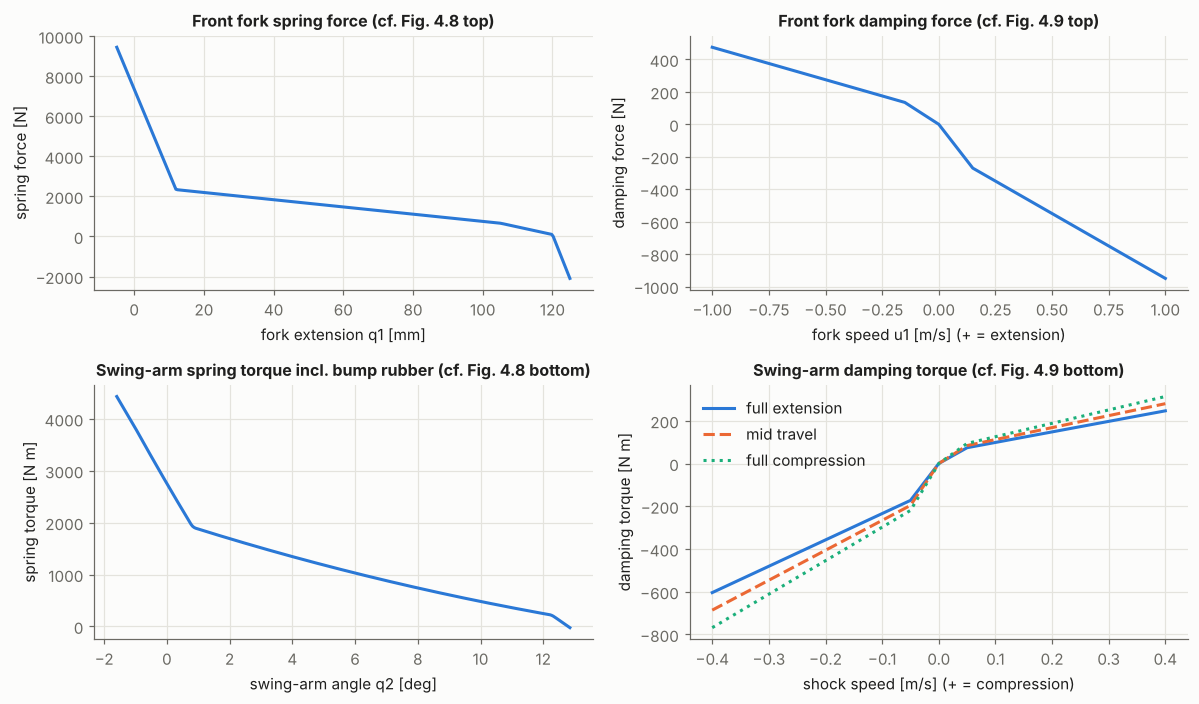

In [2]:
fork = ForkModel(travel=p.fork_travel)
rear = RearSuspension(p.Ra, p.q2_top, p.q2_bottom)
fig, ax = plt.subplots(2, 2, figsize=(11, 6.5))
q1 = np.linspace(-0.005, p.fork_travel + 0.005, 300)
ax[0, 0].plot(q1 * 1e3, fork.spring(q1)); ax[0, 0].set_xlabel("fork extension q1 [mm]"); ax[0, 0].set_ylabel("spring force [N]")
ax[0, 0].set_title("Front fork spring force (cf. Fig. 4.8 top)")
q2 = np.linspace(p.q2_bottom - 0.01, p.q2_top + 0.01, 300)
ax[1, 0].plot(np.degrees(q2), rear.spring_torque(q2)); ax[1, 0].set_xlabel("swing-arm angle q2 [deg]"); ax[1, 0].set_ylabel("spring torque [N m]")
ax[1, 0].set_title("Swing-arm spring torque incl. bump rubber (cf. Fig. 4.8 bottom)")
u1 = np.linspace(-1, 1, 201)
ax[0, 1].plot(u1, fork.damper(u1)); ax[0, 1].set_xlabel("fork speed u1 [m/s] (+ = extension)"); ax[0, 1].set_ylabel("damping force [N]")
ax[0, 1].set_title("Front fork damping force (cf. Fig. 4.9 top)")
vs = np.linspace(-0.4, 0.4, 161)
for i, (qq, lab) in enumerate([(p.q2_top, "full extension"), (0.5 * (p.q2_top + p.q2_bottom), "mid travel"), (p.q2_bottom, "full compression")]):
    T = [rear.damper_torque(qq, -v / (p.Ra * rear.lever_ratio(qq))) for v in vs]
    ax[1, 1].plot(vs, T, color=C[i], ls=["-", "--", ":"][i], label=lab)
ax[1, 1].set_xlabel("shock speed [m/s] (+ = compression)"); ax[1, 1].set_ylabel("damping torque [N m]"); ax[1, 1].legend()
ax[1, 1].set_title("Swing-arm damping torque (cf. Fig. 4.9 bottom)")
plt.tight_layout()
print(f"shock stroke {rear.stroke*1e3:.1f} mm for {(p.q2_top-p.q2_bottom)*p.Ra*1e3:.0f} mm axle travel; lever ratio {rear.lever_ratio(p.q2_top):.2f} → {rear.lever_ratio(p.q2_bottom):.2f}")

## 4.5.2 Chain tension
Under drive only the upper run is taut, on a closed throttle only the lower one. The pair of equal and opposite chain forces on frame and
swing-arm is equivalent to a torque about the pivot: chain force × perpendicular distance from the pivot to the taut run (Fig. 4.10).
That distance depends on $q_2$ only and is tabulated. The result is added to $T_{say}$.

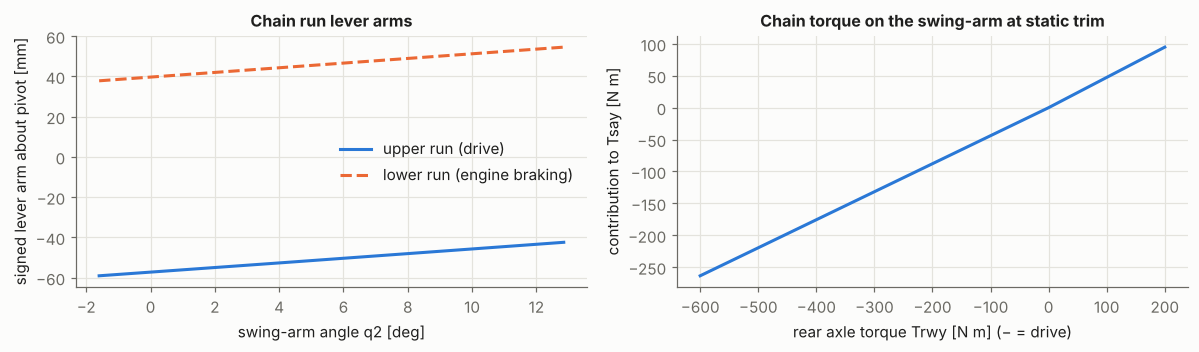

In [3]:
ch = Chain(p.Ra)
arms = np.array([[ch.lever_arms(a)["upper"], ch.lever_arms(a)["lower"]] for a in q2])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(np.degrees(q2), arms[:, 0] * 1e3, label="upper run (drive)"); ax[0].plot(np.degrees(q2), arms[:, 1] * 1e3, "--", label="lower run (engine braking)")
ax[0].set_xlabel("swing-arm angle q2 [deg]"); ax[0].set_ylabel("signed lever arm about pivot [mm]"); ax[0].legend()
ax[0].set_title("Chain run lever arms")
Tw = np.linspace(-600, 200, 81)
ax[1].plot(Tw, [ch.swingarm_torque(design["q2"], t) for t in Tw]); ax[1].set_xlabel("rear axle torque Trwy [N m] (− = drive)")
ax[1].set_ylabel("contribution to Tsay [N m]"); ax[1].set_title("Chain torque on the swing-arm at static trim")
plt.tight_layout()

A negative contribution to $T_{say}$ reduces $q_2$, i.e. chain pull under drive compresses the rear suspension about the pivot
(the axle force path that produces anti-squat acts through the tyre force and is part of the multibody equations).

## 4.5.3 / 4.5.4 Crankshaft and wheels
Engine speed is not a state, so the crank's reaction and gyroscopic torques are inputs $T_{mfx},T_{mfy},T_{mfz}$ (`crank_torques`).
Wheel gyroscopics are part of the equations of motion (notebook 4).

In [4]:
w_frame = np.array([0.3, 0.25, 0.0])        # roll and yaw rate of the frame [rad/s], body axes (a1, a2, a3)
Tx, Ty, Tz = crank_torques(w_frame, omega_crank=-12000 * 2 * np.pi / 60, domega_crank=0.0, I_crank=0.012)
print(f"12 000 rpm, I = 0.012 kg m² (estimate): Tmfx = {Tx:.1f}, Tmfy = {Ty:.1f}, Tmfz = {Tz:.1f} N m")

12 000 rpm, I = 0.012 kg m² (estimate): Tmfx = 3.8, Tmfy = -0.0, Tmfz = -4.5 N m


## 4.5.5 Drag from the coast-down test
Fit (4.2): $a=pv^2+qv+r$ with $p=-932.95\cdot10^{-6}$, $q=-2.91\cdot10^{-3}$, $r=-189.67\cdot10^{-3}$, $m=270$ kg, $\rho=1.235$ kg/m³.

Cd·A = -2 m p / rho = 0.4079 m²                (thesis: 0.4078)
F_r  = m q v + m r = -0.7857 v -51.2 N       (thesis: -0.7857 v - 51.2)
Ks (front, rear) = -11.11 -10.02  →  check with the printed slopes: -11.11 -10.02


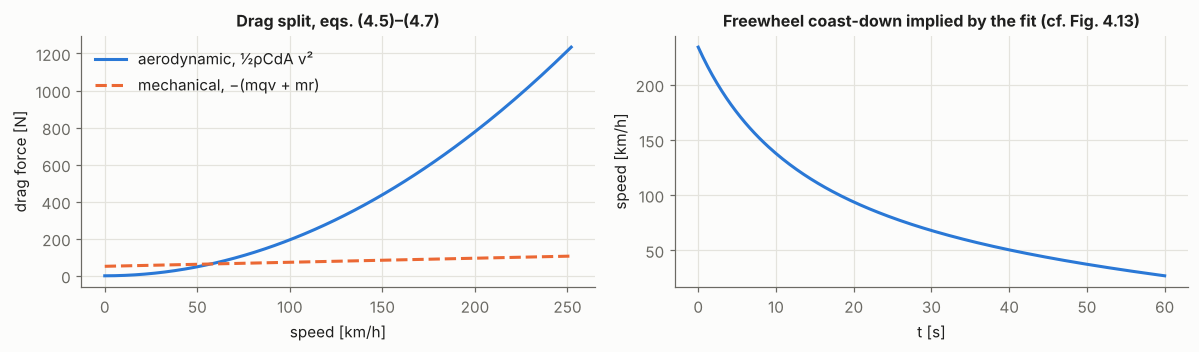

In [5]:
d = Drag()
print(f"Cd·A = -2 m p / rho = {d.CdA:.4f} m²                (thesis: 0.4078)")
print(f"F_r  = m q v + m r = {d.mass*d.q:.4f} v {d.mass*d.r:.1f} N       (thesis: -0.7857 v - 51.2)")
print("Ks (front, rear) =", d.Ks_front, d.Ks_rear, " →  check with the printed slopes:", round(-5.377 / 0.484, 2), round(-6.395 / 0.638, 2))
v = np.linspace(0, 70, 141)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(v * 3.6, d.aero(v), label="aerodynamic, ½ρCdA v²"); ax[0].plot(v * 3.6, -d.mechanical(v), "--", label="mechanical, −(mqv + mr)")
ax[0].set_xlabel("speed [km/h]"); ax[0].set_ylabel("drag force [N]"); ax[0].legend(); ax[0].set_title("Drag split, eqs. (4.5)–(4.7)")
sol = solve_ivp(lambda t, y: d.p * y**2 + d.q * y + d.r, (0, 60), [65.0], dense_output=True, rtol=1e-9)
t = np.linspace(0, 60, 200)
ax[1].plot(t, sol.sol(t)[0] * 3.6); ax[1].set_xlabel("t [s]"); ax[1].set_ylabel("speed [km/h]")
ax[1].set_title("Freewheel coast-down implied by the fit (cf. Fig. 4.13)")
plt.tight_layout()

The mechanical part is applied as axle drag torques $T_{df}=0.1F_rT_{Fz}$, $T_{dr}=0.9F_rT_{Rz}$ (`Drag.wheel_drag_torques`), the aerodynamic part at the
centre of pressure *R*. `Drag.inertial_shear` is the empirical $F=K_sIa$ relation for the tyre shear force caused by wheel inertia.

## 4.6 Rider body position
The rider's hang-off is a lateral shift $A_y$ of the mass centre of body *A*, estimated from the IMU, eq. (4.11):
$A_y=\frac{M_M}{M_A}\left(T_y+Z\,\frac{a_y}{a_z}\right)$. Because the measured accelerations were corrupted by engine vibration the thesis
substitutes surrogate channels $a_y'=1.9\,q_9$ and $a_z'=\sqrt{a_r^2-a_y'^2}$ with $a_r=g/\cos\varphi$, $\varphi=\arctan(v\omega/g)$.
In the model $A_y$ is the parameter `Py` of `BikeParams`.

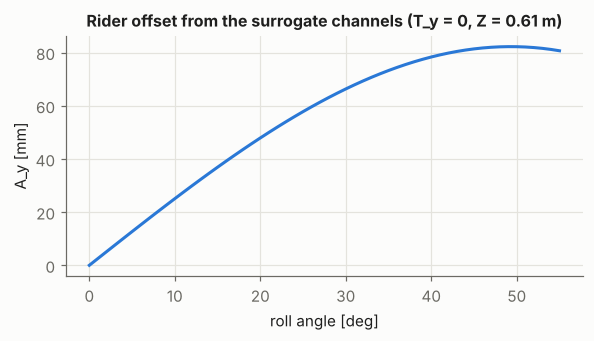

In [6]:
roll = np.radians(np.linspace(0, 55, 56)); V = 30.0
yaw_rate = 9.81 * np.tan(roll) / V                     # ideal steady turn
ay, az = surrogate_accels(roll, V, yaw_rate)
Ay = rider_offset(ay, az, Ty=0.0, Z=0.61, MM=p.total_mass, MA=p.MA)
plt.figure(figsize=(5.5, 3.2)); plt.plot(np.degrees(roll), Ay * 1e3)
plt.xlabel("roll angle [deg]"); plt.ylabel("A_y [mm]"); plt.title("Rider offset from the surrogate channels (T_y = 0, Z = 0.61 m)"); plt.tight_layout()

## 4.7 Engine torque
Wide-open-throttle and closed-throttle torque curves and the part-throttle map are given only as figures (4.20–4.22); they are needed once the
model is driven by recorded throttle data (controls session) and are not reproduced here.